In [ ]:
!pip install --upgrade keras

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 10.6 MB/s eta 0:00:00
  Attempting uninstall: keras
    Found existing installation: keras 2.15.0
    Uninstalling keras-2.15.0:
      Successfully uninstalled keras-2.15.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.15.0 requires keras<2.16,>=2.15.0, but you have keras 3.0.4 which is incompatible.


In [ ]:
import keras

print(keras.__version__)

3.0.4


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Layer (type)                       ┃ Output Shape                  ┃     Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                    │ (None, 32, 32, 32)            │         896 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ max_pooling2d (MaxPooling2D)       │ (None, 16, 16, 32)            │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dropout (Dropout)                  │ (None, 16, 16, 32)            │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ conv2d_1 (Conv2D)                  │ (None, 16, 16, 64)            │      18,496 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ max_pooling2d_1 (MaxPooling2D)     │ (None, 8, 8, 64)              │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dropout_1 (Dropout)                │ (None, 8, 8, 64)              │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ flatten (Flatten)                  │ (None, 4096)                  │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dense (Dense)                      │ (None, 512)                   │   2,097,664 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dropout_2 (Dropout)                │ (None, 512)                   │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dense_1 (Dense)                    │ (None, 10)                    │       5,130 │
└────────────────────────────────────┴───────────────────────────────┴─────────────┘

 Total params: 2,122,186 (8.10 MB)

 Trainable params: 2,122,186 (8.10 MB)

 Non-trainable params: 0 (0.00 B)

--------------------------
Epoch 1/13
313/313 - 18s - 58ms/step - accuracy: 0.3512 - loss: 1.7964 - val_accuracy: 0.4541 - val_loss: 1.5443
Epoch 2/13
313/313 - 2s - 6ms/step - accuracy: 0.5072 - loss: 1.3799 - val_accuracy: 0.5249 - val_loss: 1.3923
Epoch 3/13
313/313 - 2s - 7ms/step - accuracy: 0.5714 - loss: 1.2118 - val_accuracy: 0.6107 - val_loss: 1.0934
Epoch 4/13
313/313 - 2s - 5ms/step - accuracy: 0.6097 - loss: 1.1028 - val_accuracy: 0.6429 - val_loss: 1.0311
Epoch 5/13
313/313 - 2s - 5ms/step - accuracy: 0.6401 - loss: 1.0247 - val_accuracy: 0.6394 - val_loss: 1.0311
Epoch 6/13
313/313 - 2s - 5ms/step - accuracy: 0.6631 - loss: 0.9555 - val_accuracy: 0.6477 - val_loss: 1.0098
Epoch 7/13
313/313 - 2s - 5ms/step - accuracy: 0.6852 - loss: 0.8993 - val_accuracy: 0.6949 - val_loss: 0.8856
Epoch 8/13
313/313 - 3s - 9ms/step - accuracy: 0.7027 - loss: 0.8415 - val_accuracy: 0.6951 - val_loss: 0.8891
Epoch 9/13
313/313 - 2s - 7ms/step - accuracy: 0.7207 - loss: 0.8018 - val_accuracy

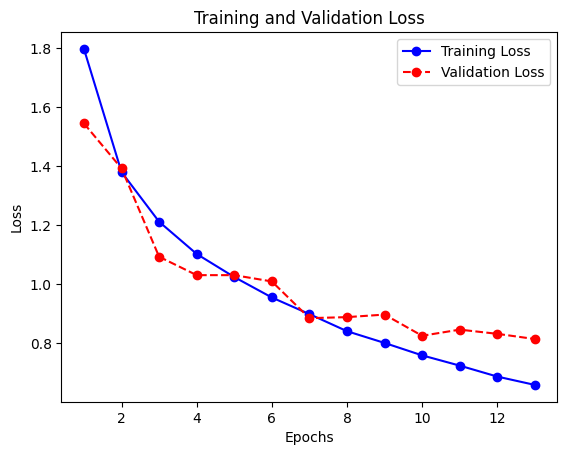

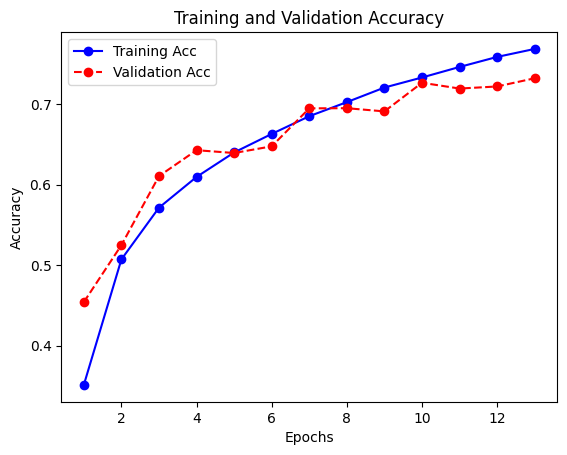

In [ ]:
import numpy as np
from keras.datasets import cifar10
from keras import Sequential
from keras.layers import Input, Dense, Flatten, Conv2D, MaxPooling2D, Dropout
from keras.utils import to_categorical
from keras import optimizers

# 指定亂數種子
np.random.seed(10)
# 載入資料集
(X_train, y_train), (X_test, y_test) = cifar10.load_data()
# 因為是固定範圍, 所以執行正規化, 從 0-255 至 0-1
X_train = X_train.astype("float32") / 255
X_test = X_test.astype("float32") / 255
# One-hot編碼
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)
# 定義模型
model = Sequential()
model.add(Input(shape=X_train.shape[1:]))
model.add(Conv2D(32, kernel_size=(3, 3), padding="same",
                 activation="relu"))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))
model.add(Conv2D(64, kernel_size=(3, 3), padding="same",
                 activation="relu"))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))
model.add(Flatten())
model.add(Dense(512, activation="relu"))
model.add(Dropout(0.5))
model.add(Dense(10, activation="softmax"))
model.summary()   # 顯示模型摘要資訊
print("--------------------------")
# 編譯模型
lr_schedule = optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.002,
    decay_steps=4000,
    decay_rate=0.96)
opt_rms = optimizers.RMSprop(learning_rate=lr_schedule)
model.compile(loss="categorical_crossentropy", optimizer=opt_rms,
              metrics=["accuracy"])
# 訓練模型
history = model.fit(X_train, y_train, validation_split=0.2,
                    epochs=13, batch_size=128, verbose=2)
# 評估模型
print("\nTesting ...")
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("測試資料集的準確度 = {:.2f}".format(accuracy))
# 顯示圖表來分析模型的訓練過程
import matplotlib.pyplot as plt
# 顯示訓練和驗證損失
loss = history.history["loss"]
epochs = range(1, len(loss)+1)
val_loss = history.history["val_loss"]
plt.plot(epochs, loss, "bo-", label="Training Loss")
plt.plot(epochs, val_loss, "ro--", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()
# 顯示訓練和驗證準確度
acc = history.history["accuracy"]
epochs = range(1, len(acc)+1)
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "bo-", label="Training Acc")
plt.plot(epochs, val_acc, "ro--", label="Validation Acc")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()